In [63]:
import emd
import utils
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from mne import (
    set_log_level,
    read_epochs,
    concatenate_epochs
)
from mne.decoding import get_spatial_filter_from_estimator
from tools.shape import extract_shape_trial, apply_func_fast_multi
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import SparsePCA
from sklearn.preprocessing import robust_scale, RobustScaler, minmax_scale, normalize
from pymer4.models import lmer, lm, glm, glmer

set_log_level("CRITICAL")

In [2]:
# access to the paths and settings
settings = utils.load_json("settings.json")
trigger_mapping = utils.load_json("trigger_mapping.json")
trigger_mapping = {int(i): trigger_mapping[i] for i in trigger_mapping.keys()}
dataset_path = Path(settings["dataset_path"])
raw_path = dataset_path.joinpath("MEG", "raw")
proc_path = dataset_path.joinpath("MEG", "processed")
beh_path = dataset_path.joinpath("BEH")

In [147]:
index = 0
subjects = [i.stem for i in utils.get_directories(proc_path, depth="one")]
subject = subjects[index]
beh_files = utils.get_files(beh_path, "*.csv", strings=["main_", subject])
beh_files = [i for i in beh_files if "ses_0" not in i._str]
fif_files = utils.get_files(proc_path, "*.fif", strings=["dots-onset", "realtime", "epo.fif", subject])
fif_files = [i for i in fif_files if "ses_0" not in i._str]
meg_calib_file = utils.get_files(proc_path, "*.json", strings=["meg-calibration", subject])[0]
meg_calib = utils.load_json(meg_calib_file)
ssd_file = utils.get_files(proc_path, "*.pkl", strings=[subject])[0]
ssd = utils.load_pickle(ssd_file)

behaviour = pd.concat([pd.read_csv(i) for i in beh_files]).reset_index(drop=True)
behaviour = behaviour[[i for i in behaviour.columns.tolist() if "exp_timing" not in i]]
behaviour = behaviour.reset_index(names=["trial"])
conditions = behaviour.groupby(["counterfactual_label", "coherence_level"]).rt.count().reset_index()
conditions = conditions[["counterfactual_label", "coherence_level"]]
behaviour = behaviour.assign(confidence_rank=0.0)
for ix, (cf, ch) in conditions.iterrows():
    selection_map = (
        (behaviour.counterfactual_label == cf) &
        (behaviour.coherence_level == ch)
    )
    ranked_confidence = behaviour[selection_map].scale_response.rank(pct=True, na_option="bottom").to_numpy()
    behaviour.loc[selection_map, "confidence_rank"] = ranked_confidence
epochs = concatenate_epochs([read_epochs(i, verbose=False) for i in fif_files], add_offset=True, on_mismatch="ignore", verbose=False)
overlap = np.mean(epochs.events[:,2] == behaviour.trial_trigger.to_numpy()) * 100
print(f"epoch order overlaps in {overlap}%")

epochs = epochs.pick(picks="mag")

alpha_components = ssd.transform(epochs.get_data())
info = epochs.info
times = epochs.times
del epochs

/tmp/ipykernel_152354/2808423995.py:26: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  epochs = concatenate_epochs([read_epochs(i, verbose=False) for i in fif_files], add_offset=True, on_mismatch="ignore", verbose=False)


epoch order overlaps in 100.0%


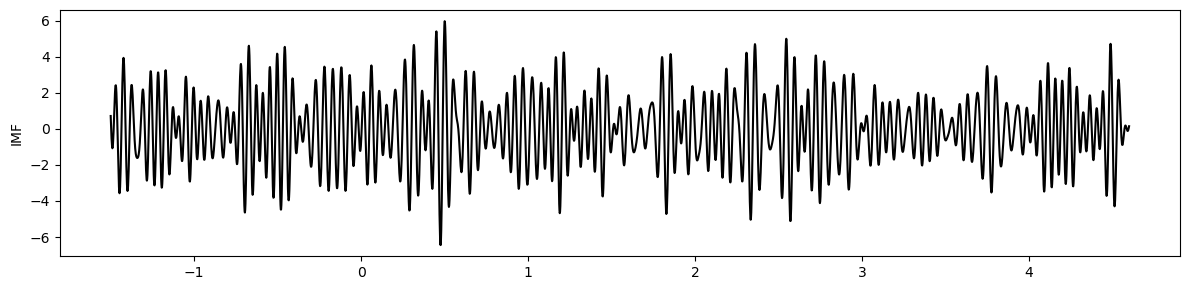

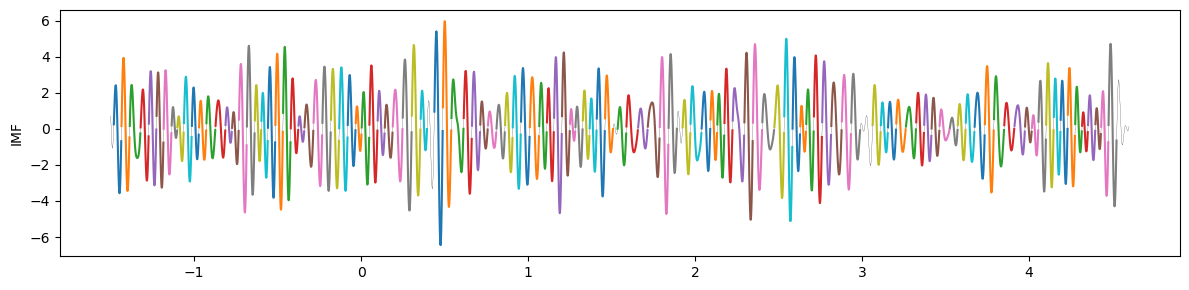

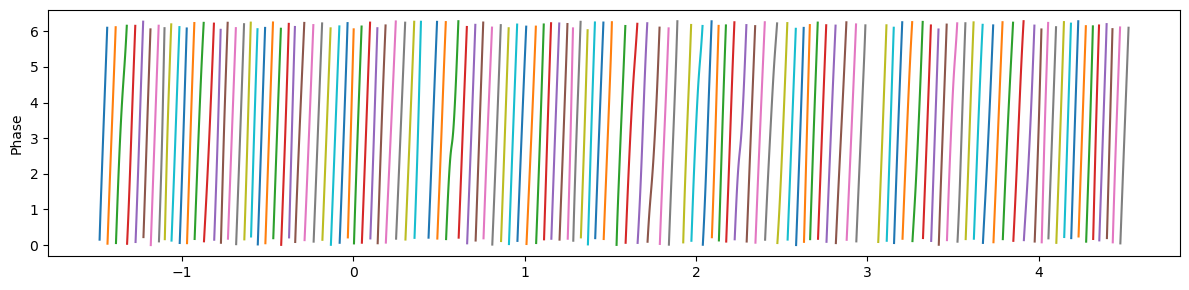

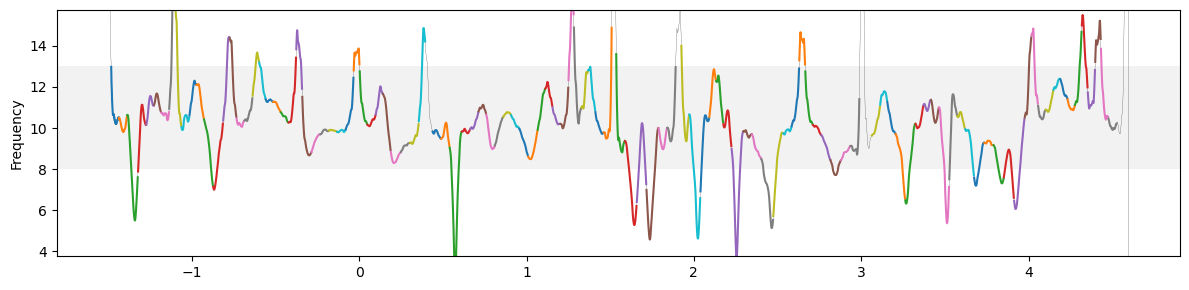

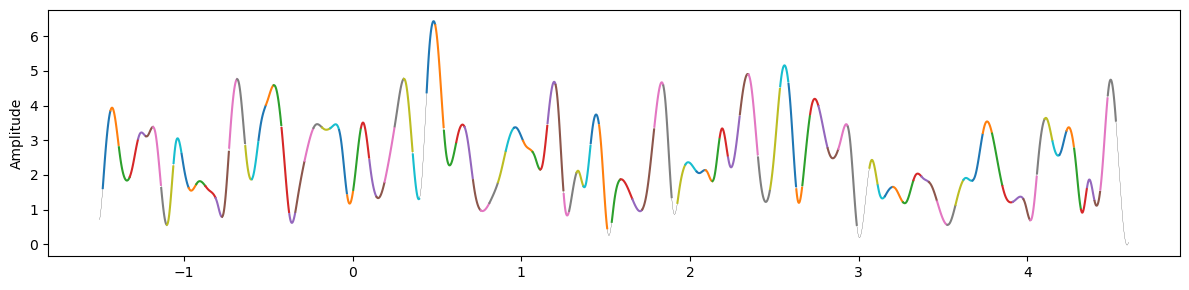

In [155]:
trial_signal = alpha_components[4, 0]
imf = emd.sift.sift(trial_signal, max_imfs=1)

IP, IF, IA = emd.spectra.frequency_transform(imf, info["sfreq"]/2, 'nht')

mask = minmax_scale(IA[:,0]) > 0.05
cycles = emd.cycles.get_cycle_vector(IP[:,0], return_good=True, mask=mask)

f, ax = plt.subplots(1, 1, figsize=(12, 3))
data = imf[:,0]
ax.plot(times, data, lw=1.5, color="black")

ax.set_ylabel("IMF")
plt.tight_layout()


f, ax = plt.subplots(1, 1, figsize=(12, 3))
data = imf[:,0]
ax.plot(times, data, lw=0.15, color="black")
for i in np.unique(cycles):
    if i != -1:
        cyc_map = cycles.flatten() == i

        ax.plot(times[cyc_map], data[cyc_map])
ax.set_ylabel("IMF")
plt.tight_layout()

f, ax = plt.subplots(1, 1, figsize=(12, 3))
data = IP[:,0]
for i in np.unique(cycles):
    if i != -1:
        cyc_map = cycles.flatten() == i

        ax.plot(times[cyc_map], data[cyc_map])
ax.set_ylabel("Phase")
plt.tight_layout()

f, ax = plt.subplots(1, 1, figsize=(12, 3))
data = IF[:,0]
ax.plot(times, data, lw=0.15, color="black")
for i in np.unique(cycles):
    if i != -1:
        cyc_map = cycles.flatten() == i

        ax.plot(times[cyc_map], data[cyc_map])
ax.set_ylabel("Frequency")
ax.set_ylim(3.75, 15.75)
ax.axhspan(8, 13, lw=0, color="black", alpha=0.05)
plt.tight_layout()

f, ax = plt.subplots(1, 1, figsize=(12, 3))
data = IA[:,0]
ax.plot(times, data, lw=0.15, color="black")
for i in np.unique(cycles):
    if i != -1:
        cyc_map = cycles.flatten() == i

        ax.plot(times[cyc_map], data[cyc_map])
ax.set_ylabel("Amplitude")
plt.tight_layout()

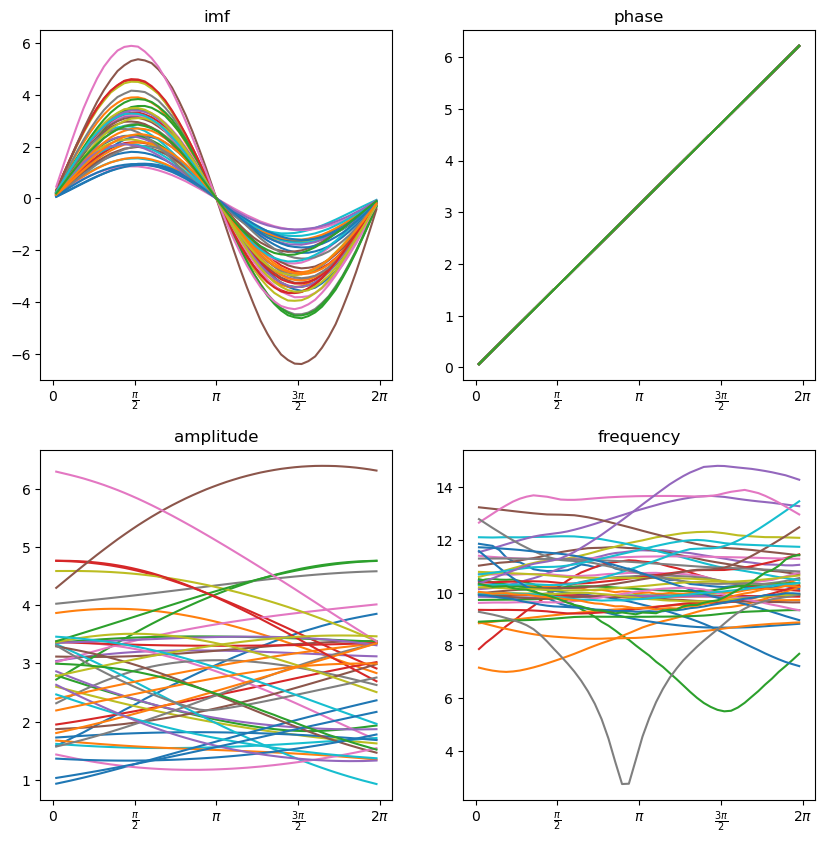

In [93]:
pa_imf, phase_template = emd.cycles.phase_align(
    IP[:, 0],
    imf[:, 0],
    cycles=cycles[:, 0]
)

pa_phase, phase_template = emd.cycles.phase_align(
    IP[:, 0],
    IP[:, 0],
    cycles=cycles[:, 0]
)

pa_amplitude, phase_template = emd.cycles.phase_align(
    IP[:, 0],
    IA[:, 0],
    cycles=cycles[:, 0]
)

pa_frequency, phase_template = emd.cycles.phase_align(
    IP[:, 0],
    IF[:, 0],
    cycles=cycles[:, 0]
)

pa_data = {
    "imf": pa_imf,
    "phase": pa_phase,
    "amplitude": pa_amplitude,
    "frequency": pa_frequency
}

f, axes = plt.subplots(2,2, figsize=(10, 10))
axes = axes.flatten()

labels = [
    "imf", "phase", "amplitude", "frequency"
]

ticks = [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi]
ticklabels = [r'$0$', r'$\frac{\pi}{2}$', r'$\pi$', r'$\frac{3\pi}{2}$', r'$2\pi$']

for ix_ax, ax in enumerate(axes):
    ax.set_title(labels[ix_ax])
    # ax.plot(phase_template, linestyle="dashed", lw=0.5)
    ax.plot(phase_template, pa_data[labels[ix_ax]])
    

    ax.set_xticks(ticks)
    ax.set_xticklabels(ticklabels)

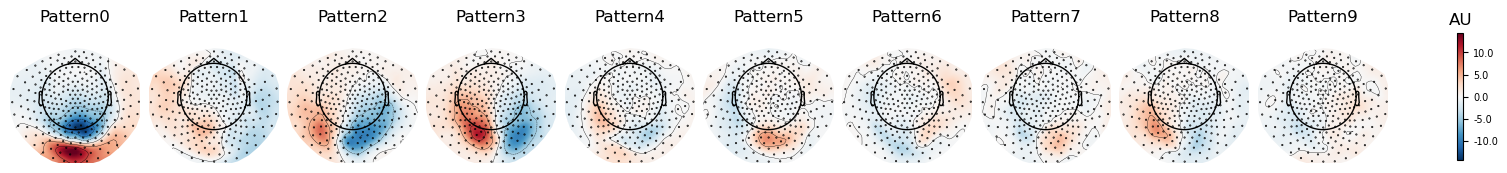

In [152]:
spf = get_spatial_filter_from_estimator(ssd, info=info)
spf.plot_patterns(components=np.arange(10));

In [118]:
trials, comps, time = alpha_components.shape

shapes = []
for trial_ix, trial in enumerate(alpha_components[:,0]):
    shapes.append(extract_shape_trial(trial, times, info["sfreq"], trial_label=trial_ix, spatial_label="ssd_001"))

shapes = pd.concat(shapes).reset_index(names=["order"])

mode_columns = [i for i in shapes.columns.tolist() if "mode_0" in i]
freq_columns = [i for i in shapes.columns.tolist() if "freq_0" in i]
amp_columns = [i for i in shapes.columns.tolist() if "amp_0" in i]

spca = SparsePCA(n_components=5)
rscal = RobustScaler()
scores = spca.fit_transform(rscal.fit_transform(shapes[mode_columns].to_numpy()))

shapes = pd.concat([shapes, pd.DataFrame.from_dict({f"spca_{ix+1}": i for ix, i in enumerate(scores.T)})], axis=1)

shapes["freq_peak"] = shapes[freq_columns].to_numpy()[np.arange(shapes.shape[0]), shapes["pa_peak_ix"].to_numpy()]
shapes["freq_trough"] = shapes[freq_columns].to_numpy()[np.arange(shapes.shape[0]), shapes["pa_trough_ix"].to_numpy()]
shapes["mode_peak"] = shapes[mode_columns].to_numpy()[np.arange(shapes.shape[0]), shapes["pa_peak_ix"].to_numpy()]
shapes["mode_trough"] = shapes[mode_columns].to_numpy()[np.arange(shapes.shape[0]), shapes["pa_trough_ix"].to_numpy()]

shapes["mean_imf"] = shapes[mode_columns].to_numpy().mean(axis=1)
shapes["mean_freq"] = shapes[freq_columns].to_numpy().mean(axis=1)
shapes["mean_amp"] = shapes[amp_columns].to_numpy().mean(axis=1)

summary_columns = [i for i in shapes.columns.tolist() if not utils.check_many(["mode_0", "freq_0", "amp_0"], i, func="any")]
summary_shape = shapes[summary_columns]
summary_shape = summary_shape.merge(behaviour, on=["trial", "trial"])



In [119]:
to_zscore = ["mean_imf", "mean_freq", "mean_amp", 'scale_response', "confidence_rank", "spca_1", "spca_2", "spca_3", "spca_4", "spca_5",  'freq_peak', 'freq_trough', 'mode_peak', 'mode_trough', 'amp_peak', 'amp_trough', "onset"]

data = summary_shape.loc[summary_shape.onset < 0.6].reset_index(drop=True)
data = data[["response_correct", 'scale_response', "confidence_rank", "spca_1", "spca_2", "spca_3", "spca_4", "spca_5",  'freq_peak', 'freq_trough', 'mode_peak', 'mode_trough', 'amp_peak', 'amp_trough', "onset", "mean_imf", "mean_freq", "mean_amp"]]
data["binary_confidence"] = (data.confidence_rank < 0.5).astype(int)
data[to_zscore] = (data[to_zscore] - data[to_zscore].mean()) / data[to_zscore].std()
data = pl.from_pandas(data)

In [122]:
model = glm(
    formula=f"binary_confidence ~ mean_imf + mean_freq + mean_amp + spca_1 + spca_2 + spca_3 + spca_4 + freq_peak + freq_trough + mode_peak + mode_trough + amp_peak + amp_trough + onset",
    data=data,
    family="binomial"
)
model.fit()

In [123]:
results = model.result_fit.to_pandas()
results["sig"] = results.p_value < 0.05

In [124]:
results

,term,estimate,std_error,conf_low,conf_high,z_stat,df,p_value,sig
0,(Intercept),-0.062106,0.014562,-0.090647,-0.033565,-4.264918,inf,1.999753e-05,True
1,mean_imf,-0.438155,0.605957,-1.625808,0.749499,-0.723079,inf,4.696314e-01,False
2,mean_freq,-0.057772,0.172478,-0.395823,0.280278,-0.334954,inf,7.376599e-01,False
3,mean_amp,-0.176188,0.395869,-0.952076,0.599701,-0.445065,inf,6.562725e-01,False
4,spca_1,0.587270,0.948085,-1.270942,2.445482,0.619428,inf,5.356348e-01,False
5,spca_2,0.154872,0.191241,-0.219952,0.529697,0.809831,inf,4.180375e-01,False
6,spca_3,-0.088178,0.267826,-0.613108,0.436752,-0.329236,inf,7.419770e-01,False
7,spca_4,1.034609,0.698230,-0.333896,2.403114,1.481760,inf,1.384042e-01,False
8,freq_peak,0.023274,0.095457,-0.163819,0.210367,0.243815,inf,8.073737e-01,False
9,freq_trough,0.054292,0.099012,-0.139769,0.248352,0.548333,inf,5.834635e-01,False


In [125]:
cont_model = glm(
    formula=f"confidence_rank ~ mean_imf + mean_freq + mean_amp + spca_1 + spca_2 + spca_3 + spca_4 + freq_peak + freq_trough + mode_peak + mode_trough + amp_peak + amp_trough + onset",
    data=data,
    family="gaussian"
)
cont_model.fit()

In [126]:
cont_results = cont_model.result_fit.to_pandas()
cont_results["sig"] = cont_results.p_value < 0.05
cont_results

,term,estimate,std_error,conf_low,conf_high,t_stat,df,p_value,sig
0,(Intercept),-1.450642e-17,0.007266,-0.014241,0.014241,-1.996558e-15,18919,1.000000,False
1,mean_imf,1.063926e-01,0.301956,-0.485469,0.698254,3.523443e-01,18919,0.724584,False
2,mean_freq,-2.987792e-02,0.086039,-0.198521,0.138765,-3.472618e-01,18919,0.728399,False
3,mean_amp,5.697744e-02,0.197363,-0.329872,0.443827,2.886937e-01,18919,0.772819,False
4,spca_1,-2.866618e-01,0.472591,-1.212983,0.639659,-6.065745e-01,18919,0.544141,False
5,spca_2,-7.408902e-02,0.095322,-0.260929,0.112751,-7.772498e-01,18919,0.437021,False
6,spca_3,-5.809120e-03,0.133539,-0.267558,0.255940,-4.350119e-02,18919,0.965302,False
7,spca_4,-5.848896e-02,0.348238,-0.741067,0.624089,-1.679568e-01,18919,0.866619,False
8,freq_peak,1.840694e-02,0.047618,-0.074928,0.111742,3.865549e-01,18919,0.699090,False
9,freq_trough,1.196025e-02,0.049390,-0.084848,0.108768,2.421617e-01,18919,0.808658,False


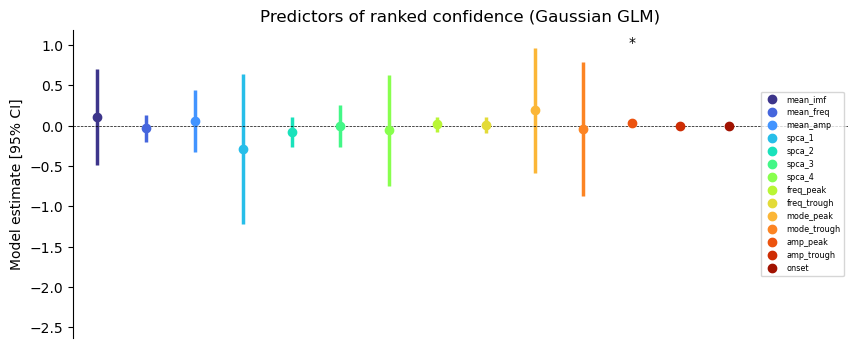

In [140]:


stats_title = "Predictors of ranked confidence (Gaussian GLM)"
res = cont_results.loc[cont_results.term != "(Intercept)"].reset_index(drop=True)

x_spot = np.linspace(0, 1, res.shape[0])
margin = np.diff(x_spot)[0]/2

pos_sig = res.conf_high.to_numpy().max() * 1.06
vals = res[["conf_low", "conf_high"]].values.flatten()
min_lat = vals.min()
max_lat = vals.max()
margin_bottom = (abs(max_lat) + abs(vals.min())) * 0.65
margin_top = (abs(max_lat) + abs(vals.min())) * 0.1


colours = plt.cm.turbo(np.linspace(0.05,0.95, num=res.shape[0]))
f, ax = plt.subplots(1, 1, figsize=(10, 4))

for index, row in res.iterrows():
    estimate = row.estimate
    err_low = abs(estimate - row.conf_low)
    err_high = abs(row.conf_high - estimate)
    ax.errorbar(
        [x_spot[index]], [estimate], 
        yerr=[[err_low], [err_high]],
        fmt="o", lw=2.5, label=row.term,
        color=colours[index]
    )
    if row.sig:
        sig = "*"
    else:
        sig = " "

    ax.text(
        x_spot[index], pos_sig, sig,
        horizontalalignment="center",
        verticalalignment="center",
    )

ax.set_xlim(0-margin, 1.15+margin)
ax.set_ylim(min_lat - margin_bottom, max_lat + margin_top)
ax.legend(fontsize="xx-small", loc=5)
ax.set_title(stats_title)
ax.set_ylabel("Model estimate [95% CI]")
ax.axhline(0, color="black", linestyle="dashed", lw=0.5)
ax.set_xticks([], minor=False)
[ax.spines[loc].set_visible(False) for loc in ["top", "right", "bottom"]];

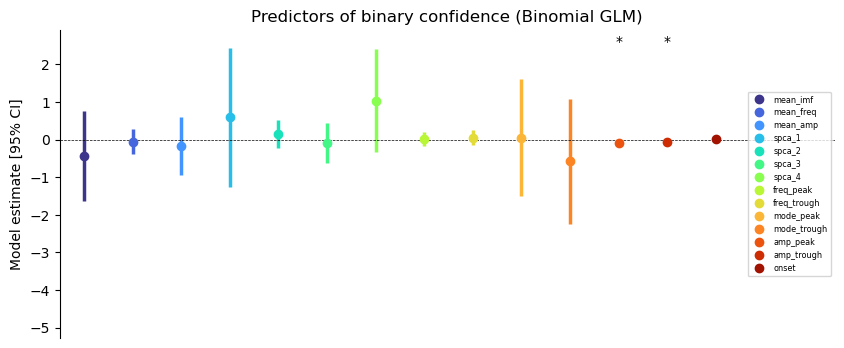

In [142]:


stats_title = "Predictors of binary confidence (Binomial GLM)"
res = results.loc[results.term != "(Intercept)"].reset_index(drop=True)

x_spot = np.linspace(0, 1, res.shape[0])
margin = np.diff(x_spot)[0]/2

pos_sig = res.conf_high.to_numpy().max() * 1.06
vals = res[["conf_low", "conf_high"]].values.flatten()
min_lat = vals.min()
max_lat = vals.max()
margin_bottom = (abs(max_lat) + abs(vals.min())) * 0.65
margin_top = (abs(max_lat) + abs(vals.min())) * 0.1


colours = plt.cm.turbo(np.linspace(0.05,0.95, num=res.shape[0]))
f, ax = plt.subplots(1, 1, figsize=(10, 4))

for index, row in res.iterrows():
    estimate = row.estimate
    err_low = abs(estimate - row.conf_low)
    err_high = abs(row.conf_high - estimate)
    ax.errorbar(
        [x_spot[index]], [estimate], 
        yerr=[[err_low], [err_high]],
        fmt="o", lw=2.5, label=row.term,
        color=colours[index]
    )
    if row.sig:
        sig = "*"
    else:
        sig = " "

    ax.text(
        x_spot[index], pos_sig, sig,
        horizontalalignment="center",
        verticalalignment="center",
    )

ax.set_xlim(0-margin, 1.15+margin)
ax.set_ylim(min_lat - margin_bottom, max_lat + margin_top)
ax.legend(fontsize="xx-small", loc=5)
ax.set_title(stats_title)
ax.set_ylabel("Model estimate [95% CI]")
ax.axhline(0, color="black", linestyle="dashed", lw=0.5)
ax.set_xticks([], minor=False)
[ax.spines[loc].set_visible(False) for loc in ["top", "right", "bottom"]];

In [160]:
summary_shape.to_csv("summary_shape.csv")